# What are the most in demand skills for the top 3 most popular data roles?

Methodology:
1. Clean-up skill column
2. Calculate skill count based on job_title_short
3. Calculate skill percentage
4. Plot the findings

In [1]:
import ast
import pandas as pd
import seaborn as sns
from datasets import load_dataset
import matplotlib.pyplot as plt

# Loading our data
dataset = load_dataset('lukebarousse/data_jobs')
df = dataset['train'].to_pandas()

# Data cleanup
df['job_posted_date'] = pd.to_datetime(df['job_posted_date'])
df['job_skills'] = df['job_skills'].apply(lambda x: ast.literal_eval(x) if pd.notna(x) else x)

c:\Users\dorac\AppData\Local\Programs\Python\Python314\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
c:\Users\dorac\AppData\Local\Programs\Python\Python314\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\dorac\.cache\huggingface\hub\datasets--lukebarousse--data_jobs. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an

In [2]:
df_RO = df[df['job_location'] == 'Romania']

In [3]:
df_skills = df_RO.explode('job_skills')

df_skills[['job_title', 'job_skills']]

,job_title,job_skills
8204,Data Engineer (all genders),python
8204,Data Engineer (all genders),java
8204,Data Engineer (all genders),golang
8204,Data Engineer (all genders),aws
8204,Data Engineer (all genders),azure
...,...,...
778022,"Associate Software Engineer, OTC Derivates Data",jira
780457,Data Integration Engineer,sql
780457,Data Integration Engineer,t-sql
780457,Data Integration Engineer,sql server


In [7]:
df_skills_count = df_skills.groupby(['job_skills', 'job_title_short']).size()

df_skills_count = df_skills_count.reset_index(name='skill_count')

df_skills_count.sort_values(by='skill_count', ascending=False, inplace=True)

df_skills_count

,job_skills,job_title_short,skill_count
364,sql,Data Engineer,62
272,python,Data Engineer,53
86,excel,Data Analyst,43
363,sql,Data Analyst,40
25,azure,Data Engineer,37
...,...,...,...
34,bash,Data Scientist,1
32,bash,Data Analyst,1
30,azure,Senior Data Scientist,1
28,azure,Senior Data Analyst,1


In [9]:
job_titles = df_skills_count['job_title_short'].unique().tolist()

job_titles = job_titles[:3]

job_titles

['Data Engineer', 'Data Analyst', 'Business Analyst']

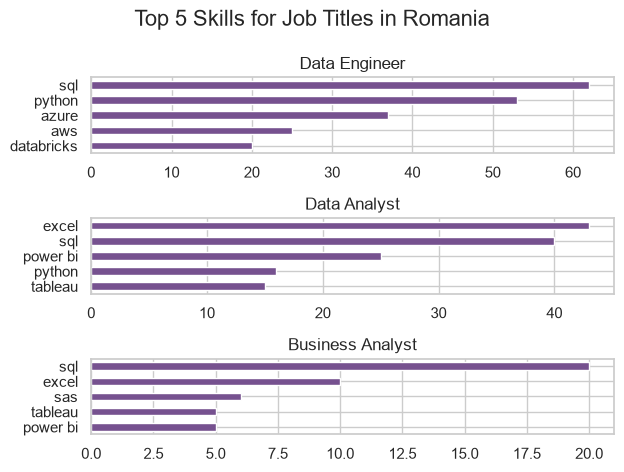

In [35]:
fig, ax = plt.subplots(len(job_titles), 1)

for i, job_title in enumerate(job_titles):
    df_plot = df_skills_count[df_skills_count['job_title_short'] == job_title].head(5)
    df_plot.plot(kind='barh', x='job_skills', y='skill_count', ax=ax[i], title=job_title, color='#76518F')
    ax[i].invert_yaxis()
    ax[i].set_ylabel('')
    ax[i].legend().set_visible(False)

fig.suptitle('Top 5 Skills for Job Titles in Romania', fontsize=16)
fig.tight_layout(h_pad=1)
plt.show()

In [17]:
df_job_title_count = df_RO['job_title_short'].value_counts().reset_index(name='jobs_total')

In [22]:
df_skills_perc = pd.merge(df_skills_count, df_job_title_count, how='left', on='job_title_short')

df_skills_perc['skill_percent'] = df_skills_perc['skill_count'] / df_skills_perc['jobs_total'] * 100

df_skills_perc 

,job_skills,job_title_short,skill_count,jobs_total,skill_percent
0,sql,Data Engineer,62,98,63.265306
1,python,Data Engineer,53,98,54.081633
2,excel,Data Analyst,43,90,47.777778
3,sql,Data Analyst,40,90,44.444444
4,azure,Data Engineer,37,98,37.755102
...,...,...,...,...,...
415,bash,Data Scientist,1,27,3.703704
416,bash,Data Analyst,1,90,1.111111
417,azure,Senior Data Scientist,1,10,10.000000
418,azure,Senior Data Analyst,1,10,10.000000


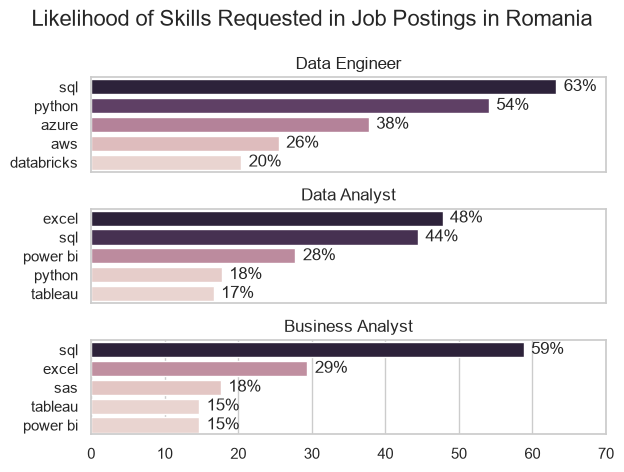

In [47]:
fig, ax = plt.subplots(len(job_titles), 1)

sns.set_theme(style="whitegrid", palette="flare")

for i, job_title in enumerate(job_titles):
    df_plot = df_skills_perc[df_skills_perc['job_title_short'] == job_title].head(5)
    sns.barplot(data=df_plot, x='skill_percent', y='job_skills', ax=ax[i], hue='skill_count')
    ax[i].set_title(job_title)
    ax[i].set_ylabel('')
    ax[i].set_xlabel('')
    ax[i].set_xlim(0, 70)
    ax[i].legend().set_visible(False)
    
    for index, value in enumerate(df_plot['skill_percent']):
        ax[i].text(value + 1, index, f'{value:.0f}%', va='center')
    
    if i != len(job_titles) - 1:
        ax[i].set_xticks([])

fig.suptitle('Likelihood of Skills Requested in Job Postings in Romania', fontsize=16)
fig.tight_layout(h_pad=1)
plt.show()